# Sales Prediction using Python
**CodeAlpha Data Science Internship — Task 4**

**Goal:** Predict product sales from the money spent on advertising on three platforms:
**TV, Radio and Newspaper**. Then use the model to find out how changes in advertising
affect sales, and what that means for marketing strategy.

**Data:** [Advertising dataset (Kaggle)](https://www.kaggle.com/datasets/bumba5341/advertisingcsv).
There are 200 markets. Advertising spend is in **thousands of dollars**, and sales are in
**thousands of units**.

**Steps:** load & clean → EDA → feature selection → train & compare regression models →
evaluate → interpret → what-if analysis for budget planning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
CHANNELS = ["TV", "Radio", "Newspaper"]

## 1. Load and clean the data

In [2]:
df = pd.read_csv("data/Advertising.csv")
print("Columns:", list(df.columns))
df.head()

Columns: ['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [3]:
# The first column is just a row number saved from the original file, so we drop it.
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df = df[[c for c in df.columns if c.strip() != ""]]
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Negative values:", int((df < 0).sum().sum()))
df.describe().round(2)

Shape: (200, 4)
Missing values:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0
Negative values: 0


,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


The data is clean: no missing values, duplicates or negative numbers.

## 2. Exploratory data analysis

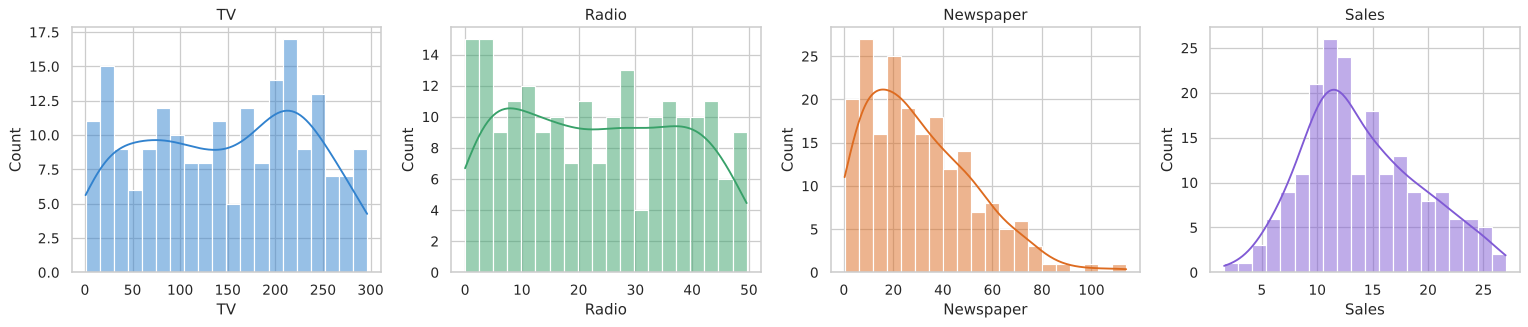

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col, color in zip(axes, CHANNELS + ["Sales"], ["#3182CE", "#38A169", "#DD6B20", "#805AD5"]):
    sns.histplot(df[col], bins=20, kde=True, ax=ax, color=color)
    ax.set_title(col)
plt.tight_layout()
fig.savefig("images/distributions.png", dpi=120, bbox_inches="tight")

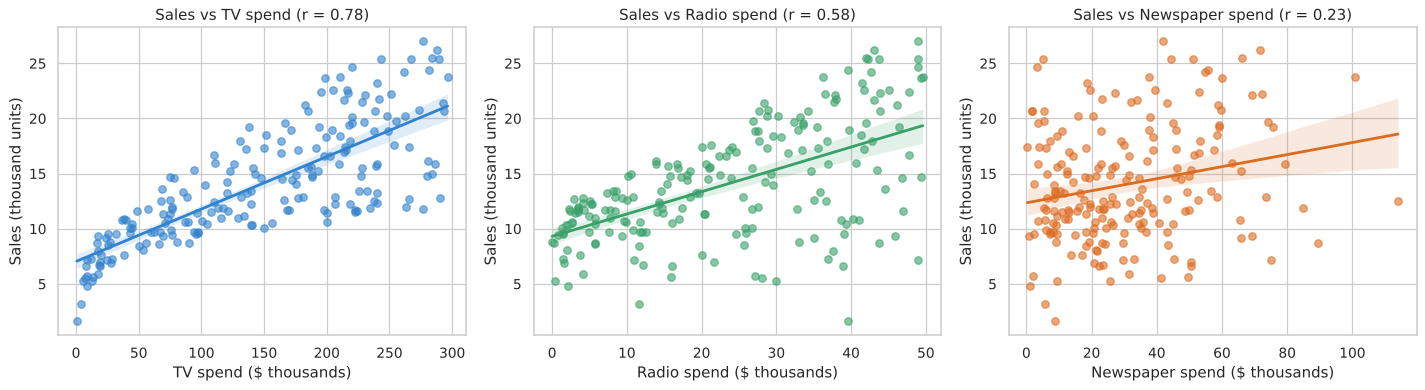

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, color in zip(axes, CHANNELS, ["#3182CE", "#38A169", "#DD6B20"]):
    sns.regplot(data=df, x=col, y="Sales", ax=ax, color=color, scatter_kws={"alpha": 0.6})
    ax.set_title(f"Sales vs {col} spend (r = {df[col].corr(df['Sales']):.2f})")
    ax.set_xlabel(f"{col} spend ($ thousands)")
    ax.set_ylabel("Sales (thousand units)")
plt.tight_layout()
fig.savefig("images/sales_vs_channels.png", dpi=120, bbox_inches="tight")

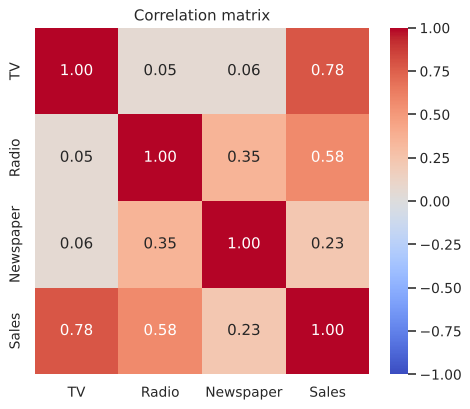

In [6]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.savefig("images/correlation.png", dpi=120, bbox_inches="tight")

**Observations**
- **TV** has the strongest relationship with sales. The relationship curves a little:
  extra TV money helps less at high spend levels (diminishing returns).
- **Radio** has a clear positive relationship too.
- **Newspaper** has only a weak link with sales. Part of that link may come from
  newspaper spend moving together with radio spend.

## 3. Train / test split

In [7]:
X = df[CHANNELS]
y = df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (160, 3) | Test: (40, 3)


## 4. Baseline: multiple linear regression
A linear model is easy to read. Each coefficient is the extra sales (in thousand units)
from spending **$1,000 more** on that channel, with the other channels kept the same.

In [8]:
lin = LinearRegression().fit(X_train, y_train)
coef = pd.Series(lin.coef_, index=CHANNELS)
print(f"Sales = {lin.intercept_:.3f} " + " ".join(f"+ {c:.4f}×{n}" for n, c in coef.items()))
print(f"\nTest R²: {r2_score(y_test, lin.predict(X_test)):.3f}")
(coef * 1000).round(1).rename("Extra units sold per extra $1,000")

Sales = 2.979 + 0.0447×TV + 0.1892×Radio + 0.0028×Newspaper

Test R²: 0.899


TV            44.7
Radio        189.2
Newspaper      2.8
Name: Extra units sold per extra $1,000, dtype: float64

### Feature selection: do we need Newspaper?
We compare cross-validated performance **with** and **without** Newspaper.

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for feats in (CHANNELS, ["TV", "Radio"], ["TV"]):
    score = cross_val_score(LinearRegression(), X_train[feats], y_train, cv=cv, scoring="r2").mean()
    print(f"{' + '.join(feats):<24} CV R² = {score:.4f}")

TV + Radio + Newspaper   CV R² = 0.8703
TV + Radio               CV R² = 0.8736
TV                       CV R² = 0.5141


If dropping Newspaper does not lower the score, then Newspaper adds no useful
information once we know TV and Radio spend. We keep the simpler TV + Radio model.

## 5. Better models
The linear model assumes each channel works separately and in a straight line. We also try:
- **Interaction + curve model:** adds `TV × Radio` (synergy: TV works better when radio
  also runs) and squared terms (diminishing returns). It is still a linear regression.
- **Random Forest** and **Gradient Boosting:** these learn non-linear patterns automatically.

In [10]:
FEATS = ["TV", "Radio"]
models = {
    "Linear (TV, Radio, Newspaper)": (LinearRegression(), CHANNELS),
    "Linear (TV, Radio)": (LinearRegression(), FEATS),
    "Interaction + curve (TV, Radio)": (make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()), FEATS),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE), CHANNELS),
    "Gradient Boosting": (GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE), CHANNELS),
}

rows, fitted = [], {}
for name, (model, feats) in models.items():
    cv_r2 = cross_val_score(model, X_train[feats], y_train, cv=cv, scoring="r2").mean()
    model.fit(X_train[feats], y_train)
    pred = model.predict(X_test[feats])
    fitted[name] = (model, feats)
    rows.append({"Model": name, "CV R² (train)": cv_r2, "Test R²": r2_score(y_test, pred),
                 "Test MAE": mean_absolute_error(y_test, pred),
                 "Test RMSE": np.sqrt(mean_squared_error(y_test, pred))})

results = pd.DataFrame(rows).sort_values("CV R² (train)", ascending=False).reset_index(drop=True)
results.round(4)

,Model,CV R² (train),Test R²,Test MAE,Test RMSE
0,"Interaction + curve (TV, Radio)",0.9816,0.9885,0.4935,0.6035
1,Gradient Boosting,0.9684,0.9835,0.6042,0.7219
2,Random Forest,0.9660,0.9826,0.6139,0.7406
3,"Linear (TV, Radio)",0.8736,0.9006,1.4443,1.7714
4,"Linear (TV, Radio, Newspaper)",0.8703,0.8994,1.4608,1.7816


In [11]:
best_name = results.loc[0, "Model"]
best_model, best_feats = fitted[best_name]
y_pred = best_model.predict(X_test[best_feats])
print(f"Best model (by cross-validation): {best_name}")
print(f"Test R²:  {r2_score(y_test, y_pred):.3f}")
print(f"Test MAE: {mean_absolute_error(y_test, y_pred):.2f} thousand units "
      f"(≈ {mean_absolute_error(y_test, y_pred) / y_test.mean():.1%} of average sales)")

Best model (by cross-validation): Interaction + curve (TV, Radio)
Test R²:  0.988
Test MAE: 0.49 thousand units (≈ 3.6% of average sales)


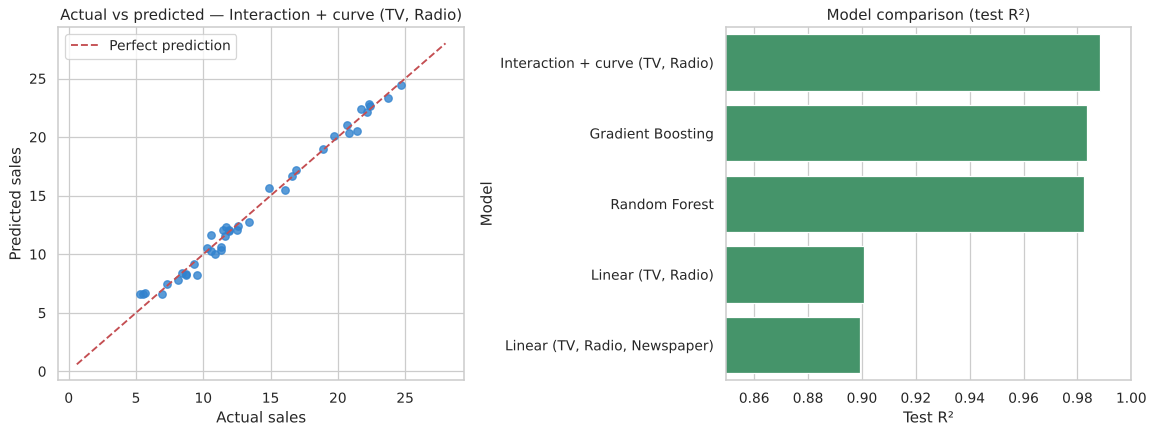

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, color="#3182CE", alpha=0.8)
lim = [y.min() - 1, y.max() + 1]
axes[0].plot(lim, lim, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual sales")
axes[0].set_ylabel("Predicted sales")
axes[0].set_title(f"Actual vs predicted — {best_name}")
axes[0].legend()
sns.barplot(data=results, y="Model", x="Test R²", ax=axes[1], color="#38A169")
axes[1].set_xlim(results["Test R²"].min() - 0.05, 1)
axes[1].set_title("Model comparison (test R²)")
plt.tight_layout()
fig.savefig("images/model_results.png", dpi=120, bbox_inches="tight")

## 6. How does advertising affect sales?
### 6a. Channel importance

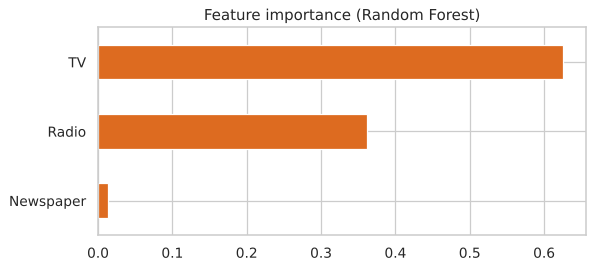

In [13]:
rf, rf_feats = fitted["Random Forest"]
pd.Series(rf.feature_importances_, index=rf_feats).sort_values().plot(kind="barh", color="#DD6B20", figsize=(7, 3))
plt.title("Feature importance (Random Forest)")
plt.savefig("images/feature_importance.png", dpi=120, bbox_inches="tight")

### 6b. Synergy between TV and Radio
Using the best model, we predict sales for many combinations of TV and Radio budgets.

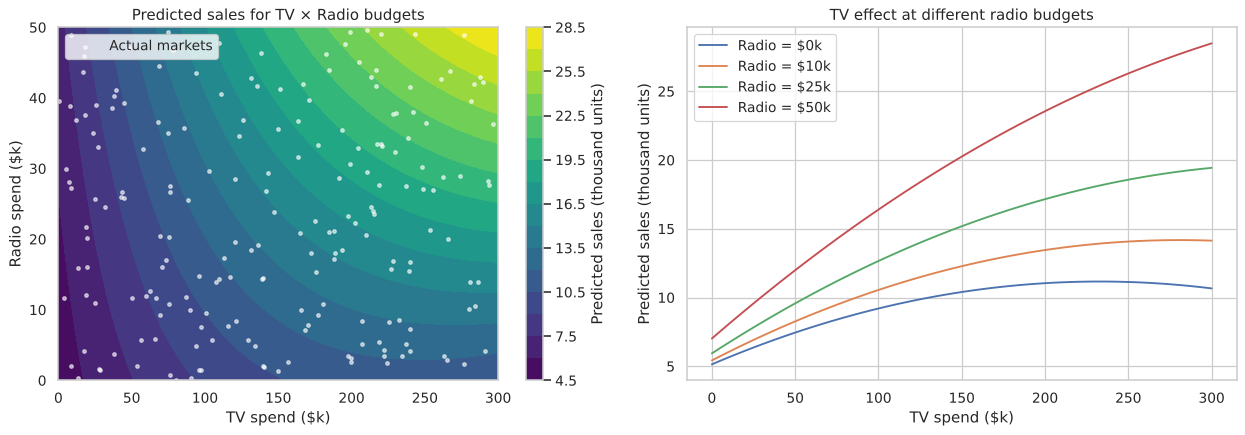

In [14]:
tv_grid = np.linspace(0, 300, 61)
radio_grid = np.linspace(0, 50, 51)
TVg, Rg = np.meshgrid(tv_grid, radio_grid)
grid = pd.DataFrame({"TV": TVg.ravel(), "Radio": Rg.ravel(), "Newspaper": df["Newspaper"].median()})
Z = best_model.predict(grid[best_feats]).reshape(TVg.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cs = axes[0].contourf(TVg, Rg, Z, levels=20, cmap="viridis")
fig.colorbar(cs, ax=axes[0], label="Predicted sales (thousand units)")
axes[0].scatter(df["TV"], df["Radio"], s=8, c="white", alpha=0.6, label="Actual markets")
axes[0].set_xlabel("TV spend ($k)")
axes[0].set_ylabel("Radio spend ($k)")
axes[0].set_title("Predicted sales for TV × Radio budgets")
axes[0].legend(loc="upper left")
for r in (0, 10, 25, 50):
    sub = grid[grid["Radio"] == r]
    axes[1].plot(sub["TV"], best_model.predict(sub[best_feats]), label=f"Radio = ${r}k")
axes[1].set_xlabel("TV spend ($k)")
axes[1].set_ylabel("Predicted sales (thousand units)")
axes[1].set_title("TV effect at different radio budgets")
axes[1].legend()
plt.tight_layout()
fig.savefig("images/tv_radio_synergy.png", dpi=120, bbox_inches="tight")

### 6c. What-if: extra $10k on one channel
Starting from a typical market (median spend), how much do sales go up if we add
$10k to one channel?

In [15]:
base = df[CHANNELS].median().to_frame().T
base_sales = best_model.predict(base[best_feats])[0]
print(f"Typical market: TV ${base['TV'][0]:.0f}k, Radio ${base['Radio'][0]:.0f}k, "
      f"Newspaper ${base['Newspaper'][0]:.0f}k -> predicted sales {base_sales:.2f}k units\n")
what_if = []
for ch in CHANNELS:
    s = base.copy()
    s[ch] += 10
    uplift = best_model.predict(s[best_feats])[0] - base_sales
    what_if.append({"Channel": ch, "Sales uplift (k units)": uplift, "Uplift %": uplift / base_sales * 100,
                    "Units per extra $1k": uplift * 1000 / 10})
what_if = pd.DataFrame(what_if)
what_if.round(2)

Typical market: TV $150k, Radio $23k, Newspaper $26k -> predicted sales 14.76k units



,Channel,Sales uplift (k units),Uplift %,Units per extra $1k
0,TV,0.42,2.83,41.70
1,Radio,1.98,13.42,198.08
2,Newspaper,0.00,0.00,0.00


### 6d. Budget reallocation for the same total spend
We keep the typical market's **total budget fixed** and try different splits.

In [16]:
total = float(base[CHANNELS].sum(axis=1)[0])
radio_max = float(df["Radio"].max())
tv0, radio0, news0 = base["TV"][0], base["Radio"][0], base["Newspaper"][0]
to_radio = min(news0, radio_max - radio0)   # radio can only go up to the highest value seen in the data
scenarios = {
    "Current (median market)": base[CHANNELS].iloc[0].to_dict(),
    "Move newspaper money to TV": {"TV": tv0 + news0, "Radio": radio0, "Newspaper": 0},
    "Move newspaper money to radio (rest to TV)": {"TV": tv0 + news0 - to_radio, "Radio": radio0 + to_radio, "Newspaper": 0},
}
# Search for the best TV/Radio split with no newspaper, keeping radio inside the range seen in the data
best_split = max(((tv, total - tv) for tv in np.arange(0, total + 1, 1.0) if total - tv <= df["Radio"].max()),
                 key=lambda s: best_model.predict(pd.DataFrame({"TV": [s[0]], "Radio": [s[1]], "Newspaper": [0]})[best_feats])[0])
scenarios["Model-optimal TV/Radio split*"] = {"TV": best_split[0], "Radio": best_split[1], "Newspaper": 0}

sc = pd.DataFrame(scenarios).T
sc["Predicted sales (k units)"] = best_model.predict(sc[best_feats])
sc["Change vs current"] = sc["Predicted sales (k units)"] - sc.loc["Current (median market)", "Predicted sales (k units)"]
print(f"Total budget held constant at ${total:.0f}k")
print("* Radio is limited to the highest radio spend seen in the data, so the model is not used outside its range.")
sc.round(2)

Total budget held constant at $198k
* Radio is limited to the highest radio spend seen in the data, so the model is not used outside its range.


,TV,Radio,Newspaper,Predicted sales (k units),Change vs current
Current (median market),149.75,22.90,25.75,14.76,0.00
Move newspaper money to TV,175.50,22.90,0.00,15.79,1.03
Move newspaper money to radio (rest to TV),149.75,48.65,0.00,19.95,5.19
Model-optimal TV/Radio split*,149.00,49.40,0.00,20.05,5.30


### 6e. Predict sales for new budget plans

In [17]:
plans = pd.DataFrame({"TV": [50, 150, 230, 100], "Radio": [10, 25, 40, 45], "Newspaper": [20, 30, 10, 5]},
                     index=["Low budget", "Balanced", "High TV + Radio", "Radio heavy"])
plans["Predicted sales (k units)"] = best_model.predict(plans[best_feats]).round(2)
plans

,TV,Radio,Newspaper,Predicted sales (k units)
Low budget,50,10,20,8.26
Balanced,150,25,30,15.18
High TV + Radio,230,40,10,22.35
Radio heavy,100,45,5,15.62


## 7. Insights for marketing strategy

1. **TV and Radio drive sales. Newspaper does not.** In the linear model, an extra $1,000 on
   radio brings about **190 extra units**, an extra $1,000 on TV brings about **45**, and an
   extra $1,000 on newspaper brings about **3**, which is basically zero. Removing Newspaper
   does not make the model worse.
2. **TV and Radio work best together.** Adding a `TV × Radio` interaction and curve terms
   raised the cross-validated R² from **0.87 to 0.98**. The test error is only about 3.6% of
   average sales. TV advertising is much more effective when radio runs alongside it.
3. **TV has diminishing returns.** The first dollars on TV give the biggest jump in sales.
   After that, each extra dollar adds less.
4. **Moving the newspaper budget pays off.** For a typical market (total budget ≈ $198k),
   the model predicts:
   - moving the newspaper budget to **TV**: about **+1.0k units** (+7%);
   - moving it to **radio**: about **+5.2k units** (+35%), with no extra spending.

**Recommendations**
- Cut or remove newspaper spend and move it to radio first, then to TV.
- Plan TV and radio campaigns **together** to get the synergy, rather than funding them separately.
- Watch for TV saturation in markets that already spend heavily on TV.
- Test these changes with a small A/B experiment in a few markets before rolling them out widely.

*Limitations:* there are only 200 markets and three channels. The data has no information on
target segment, timing, season, price or competitors, so a time-series forecast is not possible
with it. The model also should not be trusted far outside the spend ranges it has seen (for
example, radio above about $50k).